# Customer Product Recommendation Model
## Armstrong Hirwa — Data preparation, feature engineering, modelling and evaluation

**Prepared by:** Armstrong Hirwa  
**Project objective:** Combine customer social-profile information with transaction history and train a classification model to predict the product category associated with a customer.

### What this notebook does
1. Loads and inspects both source datasets.
2. Cleans customer identifiers, duplicates, missing values and data types.
3. Aggregates multiple social profiles to one row per customer.
4. Creates historical purchasing features using only earlier transactions.
5. Merges social and transaction data and validates the result.
6. Explores the merged data and defines model predictors and target.
7. Trains and evaluates a Random Forest classifier.
8. Saves the merged dataset, trained pipeline and evaluation results.

**Important:** This notebook is intentionally self-contained. It does not import functions from `product_model.py`; each stage is visible here for learning, review and presentation. Keep it in the same folder as the two CSV files.


## 1. Environment and imports

Run this cell first. If a library is missing, install it in your environment with:

```bash
pip install pandas numpy scikit-learn matplotlib seaborn joblib
```


In [32]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")

BASE_DIR = Path.cwd()
TRANSACTIONS_FILE = BASE_DIR / "customer_transactions.csv"
SOCIAL_FILE = BASE_DIR / "customer_social_profiles.csv"

print("Working folder:", BASE_DIR)
print("Transactions file exists:", TRANSACTIONS_FILE.exists())
print("Social profiles file exists:", SOCIAL_FILE.exists())


Working folder: /content
Transactions file exists: True
Social profiles file exists: True


## 2. Load the two datasets

The transaction file contains the purchase outcome we want to predict. The social-profile file contains customer signals that may help explain purchasing behaviour.


In [33]:
transactions_raw = pd.read_csv(TRANSACTIONS_FILE)
social_raw = pd.read_csv(SOCIAL_FILE)

print("Transactions shape:", transactions_raw.shape)
print("Social profiles shape:", social_raw.shape)

display(transactions_raw.head())
display(social_raw.head())


Transactions shape: (150, 6)
Social profiles shape: (155, 5)


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
0,151,1001,408,2024-01-01,Sports,2.3
1,192,1002,332,2024-01-02,Electronics,4.2
2,114,1003,442,2024-01-03,Electronics,2.1
3,171,1004,256,2024-01-04,Clothing,2.8
4,160,1005,64,2024-01-05,Clothing,1.3


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive
3,A162,Twitter,89,2.6,Positive
4,A197,Twitter,92,2.3,Neutral


## 3. Understand the raw data

Before changing anything, inspect column names, data types, missing values and duplicate rows. This helps us catch unexpected source-data issues early.


In [34]:
print("TRANSACTION COLUMNS")
print(transactions_raw.columns.tolist())
print("\nSOCIAL PROFILE COLUMNS")
print(social_raw.columns.tolist())

print("\nTRANSACTIONS INFO")
transactions_raw.info()

print("\nSOCIAL PROFILES INFO")
social_raw.info()


TRANSACTION COLUMNS
['customer_id_legacy', 'transaction_id', 'purchase_amount', 'purchase_date', 'product_category', 'customer_rating']

SOCIAL PROFILE COLUMNS
['customer_id_new', 'social_media_platform', 'engagement_score', 'purchase_interest_score', 'review_sentiment']

TRANSACTIONS INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id_legacy  150 non-null    int64  
 1   transaction_id      150 non-null    int64  
 2   purchase_amount     150 non-null    int64  
 3   purchase_date       150 non-null    object 
 4   product_category    150 non-null    object 
 5   customer_rating     140 non-null    float64
dtypes: float64(1), int64(3), object(2)
memory usage: 7.2+ KB

SOCIAL PROFILES INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 155 entries, 0 to 154
Data columns (total 5 columns):
 #   Column              

In [35]:
inspection = pd.DataFrame({
    "transactions_missing": transactions_raw.isna().sum(),
    "social_missing": social_raw.isna().sum()
})
display(inspection)

print("Exact duplicate transaction rows:", transactions_raw.duplicated().sum())
print("Exact duplicate social rows:", social_raw.duplicated().sum())


,transactions_missing,social_missing
customer_id_legacy,0.0,NaN
customer_id_new,NaN,0.0
customer_rating,10.0,NaN
engagement_score,NaN,0.0
product_category,0.0,NaN
purchase_amount,0.0,NaN
purchase_date,0.0,NaN
purchase_interest_score,NaN,0.0
review_sentiment,NaN,0.0
social_media_platform,NaN,0.0


Exact duplicate transaction rows: 0
Exact duplicate social rows: 5


## 4. Check required columns

The following cells expect the source columns listed below. If your CSV uses different names, update the names in this notebook to match the actual files before continuing.

**Transactions:** `customer_id_legacy`, `transaction_id`, `purchase_date`, `purchase_amount`, `customer_rating`, `product_category`

**Social profiles:** `customer_id_new`, `social_media_platform`, `engagement_score`, `purchase_interest_score`, `review_sentiment`


In [36]:
required_transaction_columns = {
    "customer_id_legacy", "transaction_id", "purchase_date",
    "purchase_amount", "customer_rating", "product_category"
}
required_social_columns = {
    "customer_id_new", "social_media_platform", "engagement_score",
    "purchase_interest_score", "review_sentiment"
}

missing_transaction_columns = required_transaction_columns - set(transactions_raw.columns)
missing_social_columns = required_social_columns - set(social_raw.columns)

print("Missing transaction columns:", missing_transaction_columns)
print("Missing social columns:", missing_social_columns)

if missing_transaction_columns or missing_social_columns:
    raise ValueError("Column names do not match the expected schema. Update the required column names.")


Missing transaction columns: set()
Missing social columns: set()


## 5. Clean the datasets

### Cleaning decisions
- Remove exact duplicate rows.
- Standardize both customer ID formats into a common numeric `customer_id`.
- Convert dates and numeric fields to suitable data types.
- Remove transaction rows without a usable customer ID, transaction ID or product target.
- Remove duplicate transaction IDs, keeping the first record. Confirm this is appropriate for your source data before submission.
- Keep missing social scores for now; we will impute them inside the model pipeline.


In [37]:
transactions = transactions_raw.drop_duplicates().copy()
social_profiles = social_raw.drop_duplicates().copy()

# Standardize transaction IDs, e.g. 101 -> 101
transactions["customer_id"] = pd.to_numeric(
    transactions["customer_id_legacy"].astype("string").str.strip(),
    errors="coerce"
)

# Standardize social IDs, e.g. A101 -> 101
social_profiles["customer_id"] = pd.to_numeric(
    social_profiles["customer_id_new"]
    .astype("string")
    .str.strip()
    .str.replace(r"^[A-Za-z]+", "", regex=True),
    errors="coerce"
)

# Convert transaction fields
transactions["purchase_date"] = pd.to_datetime(
    transactions["purchase_date"], errors="coerce"
)
transactions["purchase_amount"] = pd.to_numeric(
    transactions["purchase_amount"], errors="coerce"
)
transactions["customer_rating"] = pd.to_numeric(
    transactions["customer_rating"], errors="coerce"
)

# Convert social numeric fields
social_profiles["engagement_score"] = pd.to_numeric(
    social_profiles["engagement_score"], errors="coerce"
)
social_profiles["purchase_interest_score"] = pd.to_numeric(
    social_profiles["purchase_interest_score"], errors="coerce"
)

# Normalize text fields
transactions["product_category"] = (
    transactions["product_category"].astype("string").str.strip()
)
social_profiles["social_media_platform"] = (
    social_profiles["social_media_platform"].astype("string").str.strip()
)
social_profiles["review_sentiment"] = (
    social_profiles["review_sentiment"].astype("string").str.strip()
)

# Drop rows missing essential transaction fields
transactions = transactions.dropna(
    subset=["customer_id", "transaction_id", "product_category"]
).copy()
transactions = transactions[
    transactions["product_category"].ne("")
].copy()

# Drop unusable social customer IDs
social_profiles = social_profiles.dropna(subset=["customer_id"]).copy()

# Remove repeated transaction IDs
transactions = transactions.drop_duplicates(
    subset=["transaction_id"], keep="first"
).copy()

print("Clean transactions:", transactions.shape)
print("Clean social profiles:", social_profiles.shape)


Clean transactions: (150, 7)
Clean social profiles: (150, 6)


## 6. Validate customer identifiers

A merge only works when the same customer is represented consistently in both datasets. We compare unique customer IDs before merging.


In [38]:
transaction_customer_ids = set(transactions["customer_id"].dropna().unique())
social_customer_ids = set(social_profiles["customer_id"].dropna().unique())
common_customer_ids = transaction_customer_ids.intersection(social_customer_ids)

print("Unique transaction customers:", len(transaction_customer_ids))
print("Unique social customers:", len(social_customer_ids))
print("Customers present in both:", len(common_customer_ids))
print("Transaction customers without social profiles:",
      len(transaction_customer_ids - social_customer_ids))


Unique transaction customers: 75
Unique social customers: 84
Customers present in both: 61
Transaction customers without social profiles: 14


## 7. Aggregate social profiles to one row per customer

A customer may have multiple social-platform records. Joining those raw rows directly to transactions could duplicate each transaction. We aggregate social profiles so there is exactly one row per customer.

- Mean engagement and purchase-interest scores.
- Most frequent platform and sentiment.
- Number of distinct platforms.
- Number of social-profile records.


In [39]:
def most_common_value(series):
    modes = series.dropna().mode()
    return modes.iloc[0] if not modes.empty else "Unknown"

social_aggregated = (
    social_profiles.groupby("customer_id")
    .agg(
        social_media_platform=("social_media_platform", most_common_value),
        engagement_score=("engagement_score", "mean"),
        purchase_interest_score=("purchase_interest_score", "mean"),
        review_sentiment=("review_sentiment", most_common_value),
        social_platform_count=("social_media_platform", "nunique"),
        social_profile_count=("social_media_platform", "size")
    )
    .reset_index()
)

print("Aggregated social rows:", len(social_aggregated))
print("Unique aggregated customer IDs:", social_aggregated["customer_id"].nunique())
display(social_aggregated.head())


Aggregated social rows: 84
Unique aggregated customer IDs: 84


,customer_id,social_media_platform,engagement_score,purchase_interest_score,review_sentiment,social_platform_count,social_profile_count
0,100,Instagram,77.000000,4.400000,Negative,2,2
1,101,Twitter,68.000000,1.000000,Neutral,1,1
2,102,LinkedIn,51.000000,4.800000,Neutral,1,1
3,103,Instagram,64.333333,2.866667,Positive,2,3
4,104,Twitter,83.000000,2.933333,Negative,2,3


## 8. Feature engineering: historical purchase behaviour

For each transaction, create:
- `prior_purchase_count`: number of earlier transactions for that customer.
- `prior_avg_purchase_amount`: average amount from earlier transactions.
- `prior_avg_customer_rating`: average rating from earlier transactions.

We sort by customer and purchase date. `shift(1)` excludes the current transaction from its own history. The first transaction for a customer has no history and therefore receives missing historical averages; the model will impute those values.

**Important limitation:** if a transaction has no valid purchase date, its chronological position cannot be established reliably. We inspect and exclude undated rows from this time-ordered modelling workflow rather than inventing an order.


In [40]:
undated_count = transactions["purchase_date"].isna().sum()
print("Transactions with invalid/missing purchase dates:", undated_count)

transactions_model = transactions.dropna(subset=["purchase_date"]).copy()

transactions_model = transactions_model.sort_values(
    ["customer_id", "purchase_date", "transaction_id"]
).copy()

transactions_model["prior_purchase_count"] = (
    transactions_model.groupby("customer_id").cumcount()
)

transactions_model["prior_avg_purchase_amount"] = (
    transactions_model.groupby("customer_id")["purchase_amount"]
    .transform(lambda values: values.shift(1).expanding().mean())
)

transactions_model["prior_avg_customer_rating"] = (
    transactions_model.groupby("customer_id")["customer_rating"]
    .transform(lambda values: values.shift(1).expanding().mean())
)

display(transactions_model[[
    "customer_id", "purchase_date", "product_category",
    "prior_purchase_count", "prior_avg_purchase_amount",
    "prior_avg_customer_rating"
]].head(12))


Transactions with invalid/missing purchase dates: 0


,customer_id,purchase_date,product_category,prior_purchase_count,prior_avg_purchase_amount,prior_avg_customer_rating
112,100,2024-04-22,Clothing,0,NaN,NaN
146,100,2024-05-26,Books,1,172.000000,4.000000
16,101,2024-01-17,Books,0,NaN,NaN
20,101,2024-01-21,Groceries,1,271.000000,2.100000
58,101,2024-02-28,Books,2,231.500000,2.750000
72,101,2024-03-13,Books,3,290.333333,2.666667
13,102,2024-01-14,Electronics,0,NaN,NaN
44,102,2024-02-14,Electronics,1,101.000000,3.200000
145,102,2024-05-25,Sports,2,240.500000,3.800000
51,103,2024-02-21,Groceries,0,NaN,NaN


## 9. Merge transaction and social data

We use a **left join** with transactions on the left and aggregated social profiles on the right.

**Why a left join?** The target is the product category recorded in transactions. A left join retains eligible transactions even when a customer has no matching social-profile record. Missing social features are handled later by the model's imputation steps.

`validate="many_to_one"` checks that each transaction customer maps to no more than one aggregated social row.


In [41]:
merged_dataset = transactions_model.merge(
    social_aggregated,
    on="customer_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

matched_count = (merged_dataset["_merge"] == "both").sum()
unmatched_count = (merged_dataset["_merge"] == "left_only").sum()

print("Transactions before merge:", len(transactions_model))
print("Rows after merge:", len(merged_dataset))
print("Matched transaction rows:", matched_count)
print("Unmatched transaction rows:", unmatched_count)
print("Duplicate transaction IDs:", merged_dataset["transaction_id"].duplicated().sum())

if len(merged_dataset) != len(transactions_model):
    raise ValueError("Merge changed the transaction row count unexpectedly.")

if merged_dataset["transaction_id"].duplicated().any():
    raise ValueError("Duplicate transaction IDs found after merge.")

merged_dataset = merged_dataset.drop(
    columns=["_merge", "customer_id_legacy", "customer_id_new"],
    errors="ignore"
)

display(merged_dataset.head())


Transactions before merge: 150
Rows after merge: 150
Matched transaction rows: 117
Unmatched transaction rows: 33
Duplicate transaction IDs: 0


,transaction_id,purchase_amount,purchase_date,product_category,customer_rating,customer_id,prior_purchase_count,prior_avg_purchase_amount,prior_avg_customer_rating,social_media_platform,engagement_score,purchase_interest_score,review_sentiment,social_platform_count,social_profile_count
0,1113,172,2024-04-22,Clothing,4.0,100,0,NaN,NaN,Instagram,77.0,4.4,Negative,2.0,2.0
1,1147,387,2024-05-26,Books,4.6,100,1,172.0,4.00,Instagram,77.0,4.4,Negative,2.0,2.0
2,1017,271,2024-01-17,Books,2.1,101,0,NaN,NaN,Twitter,68.0,1.0,Neutral,1.0,1.0
3,1021,192,2024-01-21,Groceries,3.4,101,1,271.0,2.10,Twitter,68.0,1.0,Neutral,1.0,1.0
4,1059,408,2024-02-28,Books,2.5,101,2,231.5,2.75,Twitter,68.0,1.0,Neutral,1.0,1.0


## 10. Save and inspect the merged dataset

Save the merged data as a required deliverable. The customer ID is retained for grouping during evaluation, but it will not be used as a model predictor.


In [42]:
MERGED_FILE = BASE_DIR / "merged_dataset.csv"
merged_dataset.to_csv(MERGED_FILE, index=False)

print("Saved:", MERGED_FILE.resolve())
print("Merged dataset shape:", merged_dataset.shape)
display(merged_dataset.dtypes.to_frame("data_type"))


Saved: /content/merged_dataset.csv
Merged dataset shape: (150, 15)


,data_type
transaction_id,int64
purchase_amount,int64
purchase_date,datetime64[ns]
product_category,string[python]
customer_rating,float64
customer_id,Int64
prior_purchase_count,int64
prior_avg_purchase_amount,float64
prior_avg_customer_rating,float64
social_media_platform,string[python]


In [43]:
print("Missing values in merged dataset:")
display(merged_dataset.isna().sum().to_frame("missing_count"))

print("Product category distribution:")
display(merged_dataset["product_category"].value_counts().to_frame("transaction_count"))


Missing values in merged dataset:


,missing_count
transaction_id,0
purchase_amount,0
purchase_date,0
product_category,0
customer_rating,10
customer_id,0
prior_purchase_count,0
prior_avg_purchase_amount,75
prior_avg_customer_rating,77
social_media_platform,33


Product category distribution:


,transaction_count
product_category,
Sports,35
Electronics,34
Clothing,28
Groceries,28
Books,25


## 11. Exploratory data analysis

These plots help us understand the target distribution and social engagement values before modelling. They are descriptive, not proof of causation.


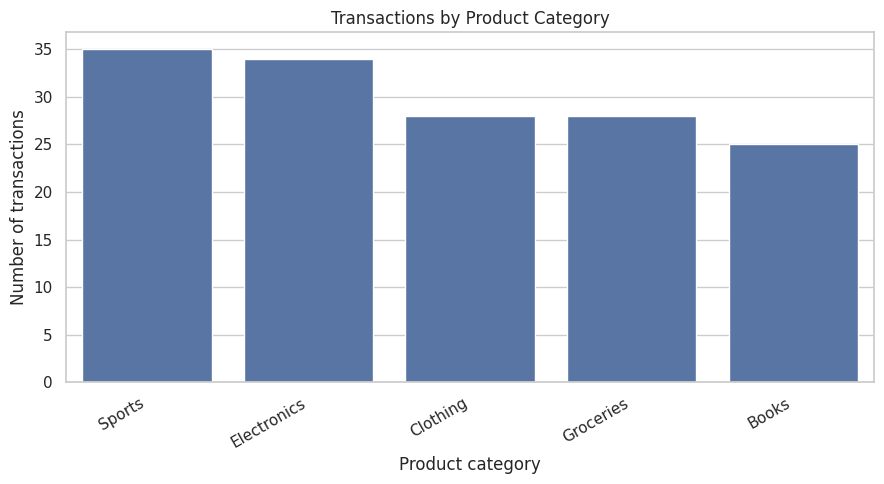

In [44]:
plt.figure(figsize=(9, 5))
category_order = merged_dataset["product_category"].value_counts().index
sns.countplot(data=merged_dataset, x="product_category", order=category_order)
plt.title("Transactions by Product Category")
plt.xlabel("Product category")
plt.ylabel("Number of transactions")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


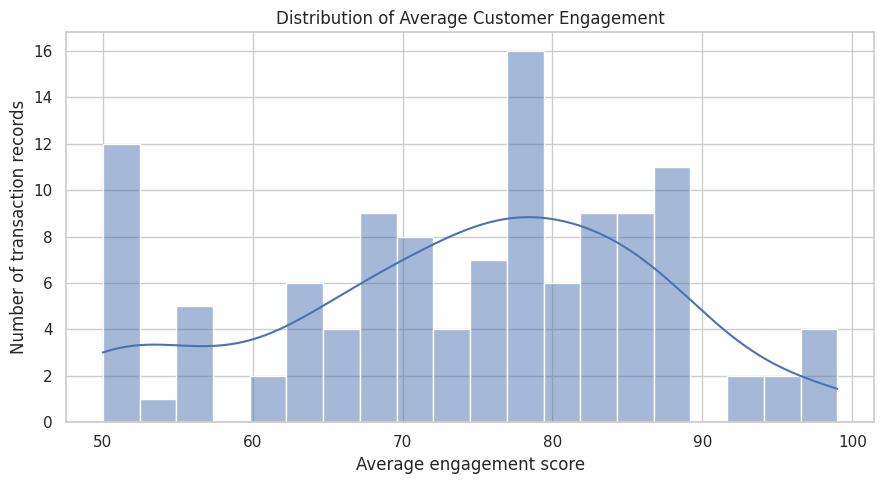

In [45]:
plt.figure(figsize=(9, 5))
sns.histplot(data=merged_dataset, x="engagement_score", bins=20, kde=True)
plt.title("Distribution of Average Customer Engagement")
plt.xlabel("Average engagement score")
plt.ylabel("Number of transaction records")
plt.tight_layout()
plt.show()


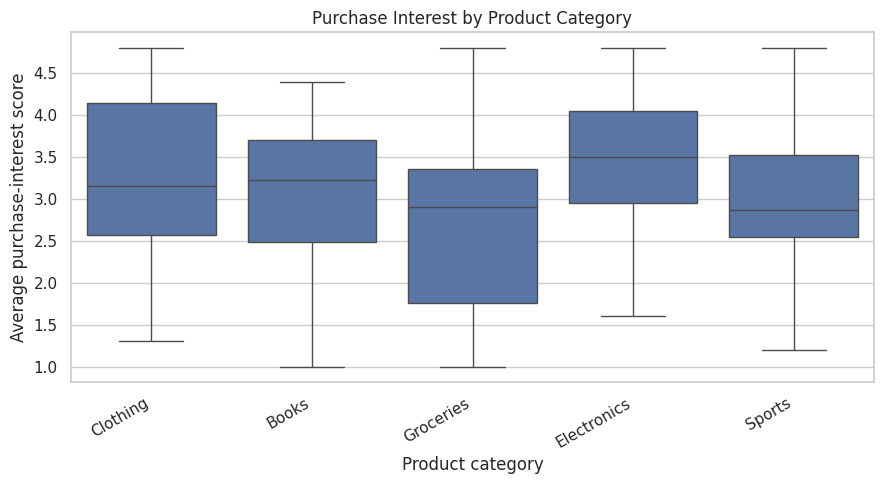

In [46]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=merged_dataset, x="product_category", y="purchase_interest_score")
plt.title("Purchase Interest by Product Category")
plt.xlabel("Product category")
plt.ylabel("Average purchase-interest score")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


## 12. Define features (`X`) and target (`y`)

The model predicts `product_category`.

Predictors include social engagement, purchase interest, platform usage and historical purchasing behaviour. We deliberately exclude:
- `product_category` from `X`, because it is the target.
- `purchase_amount` and `customer_rating` for the current transaction, because they are only known after the purchase.
- customer and transaction IDs, because they identify records rather than describe behaviour.

**Prediction-time check:** social features must also be available before the recommendation is made. If a review sentiment or engagement score was collected after the transaction, remove it or reconstruct a time-valid version.


In [47]:
numeric_features = [
    "engagement_score",
    "purchase_interest_score",
    "social_platform_count",
    "social_profile_count",
    "prior_purchase_count",
    "prior_avg_purchase_amount",
    "prior_avg_customer_rating"
]

categorical_features = [
    "social_media_platform",
    "review_sentiment"
]

feature_columns = numeric_features + categorical_features

X = merged_dataset[feature_columns].copy()
y = merged_dataset["product_category"].astype(str).copy()
groups = merged_dataset["customer_id"].copy()

print("Predictor columns:", feature_columns)
print("Number of predictor rows:", len(X))
print("Target classes:", sorted(y.unique()))
display(y.value_counts().to_frame("count"))


Predictor columns: ['engagement_score', 'purchase_interest_score', 'social_platform_count', 'social_profile_count', 'prior_purchase_count', 'prior_avg_purchase_amount', 'prior_avg_customer_rating', 'social_media_platform', 'review_sentiment']
Number of predictor rows: 150
Target classes: ['Books', 'Clothing', 'Electronics', 'Groceries', 'Sports']


,count
product_category,
Sports,35
Electronics,34
Clothing,28
Groceries,28
Books,25


## 13. Split training and testing data by customer

A random row split could place transactions from the same customer in both sets. That can make evaluation too optimistic. We use `GroupShuffleSplit` to keep each customer's records together.

We search for a split where every target class appears in both sets. If the dataset is too small or classes are concentrated among too few customers, no valid split may exist; in that case, more data or a different evaluation design is needed.


In [48]:
all_classes = set(y.unique())
selected_split = None

for seed in range(1000):
    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.25,
        random_state=seed
    )
    train_idx, test_idx = next(splitter.split(X, y, groups))

    if (set(y.iloc[train_idx]) == all_classes
            and set(y.iloc[test_idx]) == all_classes):
        selected_split = (train_idx, test_idx)
        break

if selected_split is None:
    raise ValueError(
        "Could not create a customer-level split containing every class "
        "in both sets. Review class counts and the number of customers."
    )

train_idx, test_idx = selected_split
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

train_customers = set(groups.iloc[train_idx])
test_customers = set(groups.iloc[test_idx])

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training customers:", len(train_customers))
print("Testing customers:", len(test_customers))
print("Customer overlap:", len(train_customers.intersection(test_customers)))

assert train_customers.isdisjoint(test_customers)


Training rows: 110
Testing rows: 40
Training customers: 56
Testing customers: 19
Customer overlap: 0


In [49]:
split_summary = pd.DataFrame({
    "training": y_train.value_counts(),
    "testing": y_test.value_counts()
}).fillna(0).astype(int)
display(split_summary)


,training,testing
product_category,,
Books,20,5
Clothing,20,8
Electronics,22,12
Groceries,21,7
Sports,27,8


## 14. Build the preprocessing and Random Forest pipeline

The numerical pipeline imputes missing values with the median and scales numeric values. The categorical pipeline imputes missing values with the most frequent category and one-hot encodes categories.

The `Pipeline` ensures these transformations are fitted on training data only. Random Forest combines predictions from multiple decision trees.


In [50]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced",
        min_samples_leaf=2
    ))
])

print(model)


Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['engagement_score',
                                                   'purchase_interest_score',
                                                   'social_platform_count',
                                                   'social_profile_count',
                                                   'prior_purchase_count',
                                                   'prior_avg_purchase_amount',
                                                   'prior_avg_customer_rating']),
                       

## 15. Train the model

`fit()` learns relationships between the predictor columns and product categories using training data only.


In [51]:
# Convert Pandas nullable dtypes and pd.NA values to standard NumPy representation
X_train_clean = X_train.copy()
X_train_clean = X_train_clean.replace({pd.NA: np.nan})

for col in numeric_features:
    X_train_clean[col] = X_train_clean[col].astype(float)
for col in categorical_features:
    # Convert to standard string object, filling pd.NA/NaN with a fallback string
    # because SimpleImputer's 'most_frequent' strategy needs to check values safely
    X_train_clean[col] = X_train_clean[col].astype(object).fillna(np.nan)

# Do the same for test set
X_test_clean = X_test.copy()
X_test_clean = X_test_clean.replace({pd.NA: np.nan})

for col in numeric_features:
    X_test_clean[col] = X_test_clean[col].astype(float)
for col in categorical_features:
    X_test_clean[col] = X_test_clean[col].astype(object).fillna(np.nan)

# Fit model using the standard-typed training data
model.fit(X_train_clean, y_train)
print("Random Forest training completed.")

# Re-assign back to original variables so subsequent cells run without any modification
X_train = X_train_clean
X_test = X_test_clean

Random Forest training completed.


## 16. Generate predictions and probabilities

`predict()` returns the predicted category. `predict_proba()` returns the model's estimated probability for each class.


In [52]:
predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)

prediction_comparison = pd.DataFrame({
    "actual_category": y_test.reset_index(drop=True),
    "predicted_category": predictions
})
display(prediction_comparison.head(15))


,actual_category,predicted_category
0,Books,Sports
1,Electronics,Groceries
2,Sports,Sports
3,Electronics,Electronics
4,Clothing,Books
5,Sports,Electronics
6,Electronics,Groceries
7,Electronics,Sports
8,Electronics,Electronics
9,Clothing,Sports


## 17. Evaluate model performance

We calculate accuracy, weighted precision, weighted recall, weighted F1-score and log loss.

- Accuracy: fraction of test predictions that are correct.
- Precision: among predictions for a class, how many were correct.
- Recall: among actual examples of a class, how many were found.
- F1-score: harmonic mean of precision and recall.
- Log loss: evaluates the quality of predicted probabilities; lower is better.

Weighted averages account for the number of test examples in each class. Because this dataset is small, report the test-set size alongside the scores and avoid claiming that one split proves general performance.


In [53]:
accuracy = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions, average="weighted", zero_division=0)
recall = recall_score(y_test, predictions, average="weighted", zero_division=0)
f1 = f1_score(y_test, predictions, average="weighted", zero_division=0)
loss = log_loss(y_test, probabilities, labels=model.classes_)

evaluation_results = {
    "accuracy": accuracy,
    "precision_weighted": precision,
    "recall_weighted": recall,
    "f1_weighted": f1,
    "log_loss": loss
}

metrics_table = pd.DataFrame([
    {"Metric": "Accuracy", "Value": accuracy},
    {"Metric": "Weighted precision", "Value": precision},
    {"Metric": "Weighted recall", "Value": recall},
    {"Metric": "Weighted F1-score", "Value": f1},
    {"Metric": "Log loss", "Value": loss}
])
display(metrics_table.style.format({"Value": "{:.4f}"}))


,Metric,Value
0,Accuracy,0.2000
1,Weighted precision,0.2407
2,Weighted recall,0.2000
3,Weighted F1-score,0.2093
4,Log loss,1.8012


In [54]:
print(classification_report(y_test, predictions, zero_division=0))


              precision    recall  f1-score   support

       Books       0.09      0.20      0.12         5
    Clothing       0.17      0.12      0.14         8
 Electronics       0.43      0.25      0.32        12
   Groceries       0.22      0.29      0.25         7
      Sports       0.14      0.12      0.13         8

    accuracy                           0.20        40
   macro avg       0.21      0.20      0.19        40
weighted avg       0.24      0.20      0.21        40



## 18. Confusion matrix

Rows are actual categories and columns are predicted categories. The diagonal contains correct predictions; off-diagonal cells show categories the model confused.


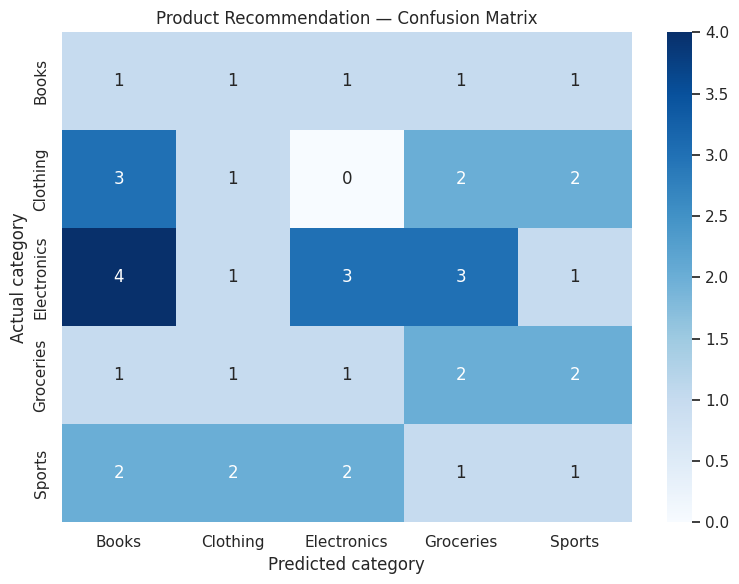

In [55]:
class_labels = list(model.classes_)
cm = confusion_matrix(y_test, predictions, labels=class_labels)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_labels, yticklabels=class_labels
)
plt.title("Product Recommendation — Confusion Matrix")
plt.xlabel("Predicted category")
plt.ylabel("Actual category")
plt.tight_layout()
plt.show()


## 19. Example product recommendation

This demonstrates how one held-out customer record can be passed to the trained pipeline. The probabilities are model estimates, not guarantees that a customer will purchase a product.


In [56]:
example_customer = X_test.iloc[[0]]
example_prediction = model.predict(example_customer)[0]
example_probabilities = model.predict_proba(example_customer)[0]

recommendation_table = (
    pd.DataFrame({
        "product_category": model.classes_,
        "estimated_probability": example_probabilities
    })
    .sort_values("estimated_probability", ascending=False)
    .reset_index(drop=True)
)

print("Predicted category:", example_prediction)
display(recommendation_table.style.format({
    "estimated_probability": "{:.2%}"
}))


Predicted category: Sports


,product_category,estimated_probability
0,Sports,27.56%
1,Groceries,21.53%
2,Electronics,21.48%
3,Books,17.13%
4,Clothing,12.30%


## 20. Inspect Random Forest feature importance

Feature importance offers one view of which transformed predictors the fitted forest used most. It is not a causal explanation and can be biased when predictors are correlated.


,feature,importance
1,numeric__purchase_interest_score,0.177094
0,numeric__engagement_score,0.157186
5,numeric__prior_avg_purchase_amount,0.144273
6,numeric__prior_avg_customer_rating,0.132662
4,numeric__prior_purchase_count,0.073418
3,numeric__social_profile_count,0.047834
12,categorical__review_sentiment_Negative,0.041981
7,categorical__social_media_platform_Facebook,0.035270
9,categorical__social_media_platform_LinkedIn,0.033168
2,numeric__social_platform_count,0.032669


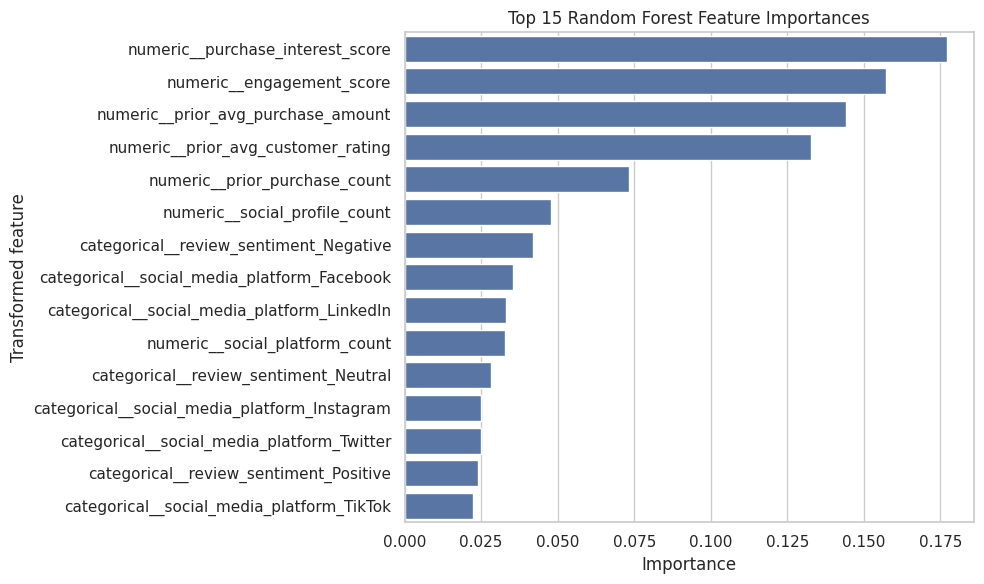

In [57]:
fitted_preprocessor = model.named_steps["preprocessing"]
fitted_forest = model.named_steps["classifier"]
transformed_feature_names = fitted_preprocessor.get_feature_names_out()

importance_table = (
    pd.DataFrame({
        "feature": transformed_feature_names,
        "importance": fitted_forest.feature_importances_
    })
    .sort_values("importance", ascending=False)
    .head(15)
)

display(importance_table)
plt.figure(figsize=(10, 6))
sns.barplot(data=importance_table, x="importance", y="feature")
plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Transformed feature")
plt.tight_layout()
plt.show()


## 21. Save the required deliverables

The saved artifact includes the fitted preprocessing pipeline and classifier. The evaluation text file records the measured test metrics and classification report. These files are created in the notebook's working directory.


In [58]:
MERGED_FILE = BASE_DIR / "merged_dataset.csv"
MODEL_FILE = BASE_DIR / "product_recommendation_model.joblib"
RESULTS_FILE = BASE_DIR / "evaluation_results.txt"

merged_dataset.to_csv(MERGED_FILE, index=False)

model_package = {
    "model": model,
    "feature_columns": feature_columns,
    "classes": list(model.classes_)
}
joblib.dump(model_package, MODEL_FILE)

with open(RESULTS_FILE, "w", encoding="utf-8") as file:
    file.write("PRODUCT RECOMMENDATION MODEL — EVALUATION RESULTS\n")
    file.write("=" * 55 + "\n")
    file.write(f"Test rows: {len(X_test)}\n")
    file.write(f"Test customers: {len(test_customers)}\n")
    for metric_name, metric_value in evaluation_results.items():
        file.write(f"{metric_name}: {metric_value:.4f}\n")
    file.write("\nCLASSIFICATION REPORT\n")
    file.write(classification_report(y_test, predictions, zero_division=0))

print("Saved merged dataset:", MERGED_FILE.resolve())
print("Saved model:", MODEL_FILE.resolve())
print("Saved evaluation:", RESULTS_FILE.resolve())


Saved merged dataset: /content/merged_dataset.csv
Saved model: /content/product_recommendation_model.joblib
Saved evaluation: /content/evaluation_results.txt


## 22. Verify saved files and model loading

Finally, check that the output files exist and load the saved model package. This is a basic persistence check.


In [59]:
for output_file in [MERGED_FILE, MODEL_FILE, RESULTS_FILE]:
    print(output_file.name, "| exists:", output_file.exists(),
          "| bytes:", output_file.stat().st_size if output_file.exists() else 0)

loaded_package = joblib.load(MODEL_FILE)
loaded_model = loaded_package["model"]

loaded_prediction = loaded_model.predict(example_customer)
print("Prediction from reloaded model:", loaded_prediction[0])
print("Matches original prediction:", loaded_prediction[0] == example_prediction)


merged_dataset.csv | exists: True | bytes: 11962
product_recommendation_model.joblib | exists: True | bytes: 1624976
evaluation_results.txt | exists: True | bytes: 757
Prediction from reloaded model: Sports
Matches original prediction: True
